# CodeAlpha — Exploratory Data Analysis

## Task 2: Data Analytics Internship

**Project by:** Kartik Singh

**Objective:** To explore and analyse a book dataset, identify patterns, examine variables and discover useful insights using Python.

## 1. Importing Libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Loading the Dataset

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving books_dataset.csv to books_dataset.csv


In [ ]:
df = pd.read_csv("books_dataset.csv")

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,Title,Price,Rating,Availability
0,A Light in the Attic,£51.77,Three,In stock
1,Tipping the Velvet,£53.74,One,In stock
2,Soumission,£50.10,One,In stock
3,Sharp Objects,£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock


## 3. Understanding the Dataset

In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Shape: (20, 4)

Column Names:
Index(['Title', 'Price', 'Rating', 'Availability'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Title         20 non-null     object
 1   Price         20 non-null     object
 2   Rating        20 non-null     object
 3   Availability  20 non-null     object
dtypes: object(4)
memory usage: 772.0+ bytes

Statistical Summary:


,Title,Price,Rating,Availability
count,20,20,20,20
unique,20,20,5,1
top,A Light in the Attic,£51.77,One,In stock
freq,1,1,6,20


## 4. Checking for Missing Values

In [ ]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values in Each Column:
Title           0
Price           0
Rating          0
Availability    0
dtype: int64

Total Missing Values:
0


## 5. Analysing Book Ratings

Book Rating Distribution:
Rating
One      6
Five     4
Four     4
Three    3
Two      3
Name: count, dtype: int64


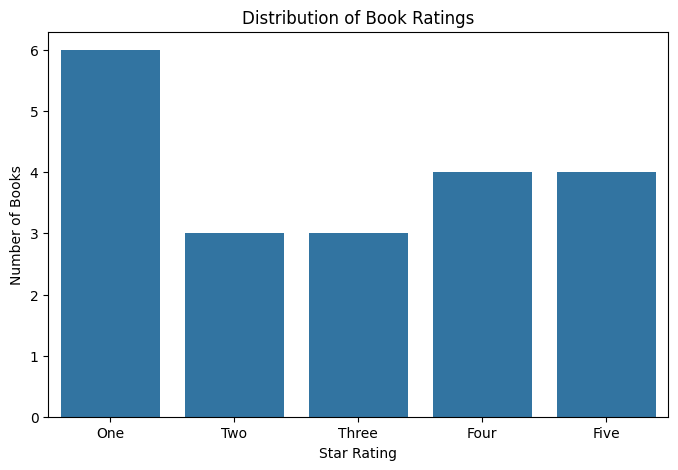

In [ ]:
print("Book Rating Distribution:")
print(df["Rating"].value_counts())

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Rating", order=["One", "Two", "Three", "Four", "Five"])

plt.title("Distribution of Book Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.show()

## 6. Analysing Book Prices

Average Price: 38.048500000000004
Highest Price: 57.25
Lowest Price: 13.99


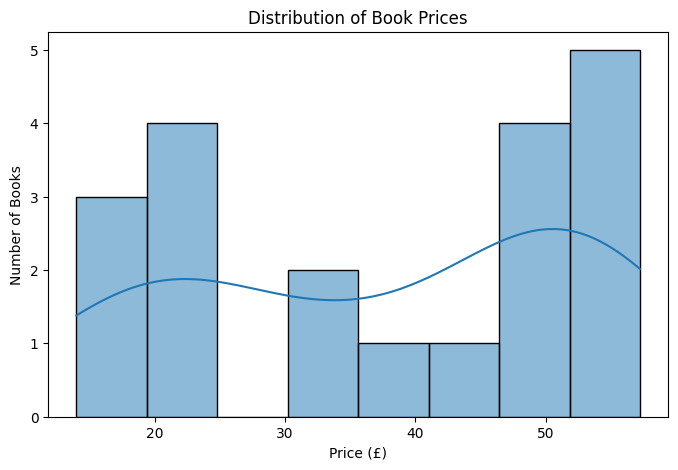

In [ ]:
# Convert prices into numeric values
df["Price"] = df["Price"].str.replace("£", "", regex=False).astype(float)

print("Average Price:", df["Price"].mean())
print("Highest Price:", df["Price"].max())
print("Lowest Price:", df["Price"].min())

plt.figure(figsize=(8, 5))
sns.histplot(df["Price"], bins=8, kde=True)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.show()

## 7. Analysing Book Availability

Book Availability:
Availability
In stock    20
Name: count, dtype: int64


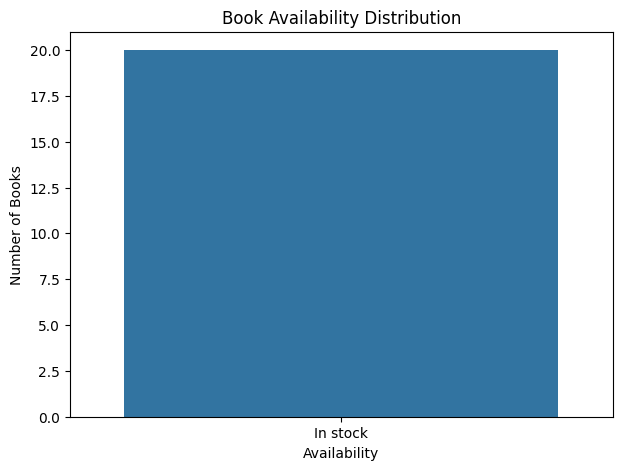

In [ ]:
print("Book Availability:")
print(df["Availability"].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Availability")

plt.title("Book Availability Distribution")
plt.xlabel("Availability")
plt.ylabel("Number of Books")
plt.show()

## 8. Relationship Between Book Price and Rating

Correlation between Price and Rating:
-0.07585689715186737


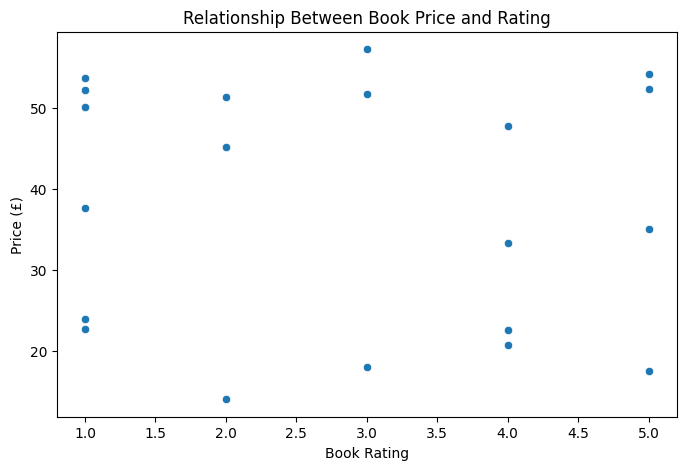

In [ ]:
rating_order = ["One", "Two", "Three", "Four", "Five"]

df["Rating_Number"] = df["Rating"].map({
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
})

print("Correlation between Price and Rating:")
print(df["Price"].corr(df["Rating_Number"]))

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Rating_Number", y="Price")

plt.title("Relationship Between Book Price and Rating")
plt.xlabel("Book Rating")
plt.ylabel("Price (£)")
plt.show()

## 9. Average Price by Book Rating

Average Price for Each Rating:
Rating
Five     39.750000
Four     31.105000
One      40.018333
Three    42.316667
Two      36.830000
Name: Price, dtype: float64


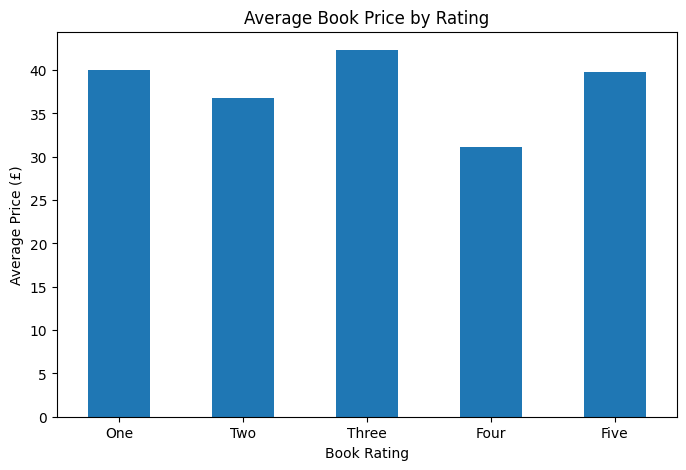

In [ ]:
average_price = df.groupby("Rating")["Price"].mean()

print("Average Price for Each Rating:")
print(average_price)

average_price = average_price.reindex(
    ["One", "Two", "Three", "Four", "Five"]
)

plt.figure(figsize=(8, 5))
average_price.plot(kind="bar")

plt.title("Average Book Price by Rating")
plt.xlabel("Book Rating")
plt.ylabel("Average Price (£)")
plt.xticks(rotation=0)
plt.show()

## 10. Detecting Price Outliers